# 2021 — CLIP: Contrastive Language–Image Pre-training

**Paper:** Alec Radford et al., *"Learning Transferable Visual Models From Natural Language Supervision"* (2021).

Train an **image encoder** and a **text encoder** together so that matching (image, caption) pairs have similar embeddings. For a batch of $N$ pairs, compute the $N\times N$ cosine-similarity matrix and apply a symmetric cross-entropy (the **InfoNCE** loss): each image should pick out its own caption and vice versa.

$$\mathcal L = \tfrac12\left[\operatorname{CE}(S, \text{diag}) + \operatorname{CE}(S^\top, \text{diag})\right], \qquad S_{ij} = \frac{\langle f(x_i), g(t_j)\rangle}{\tau}$$

The payoff is **zero-shot classification**: write a caption for each class ("a photo of a dog") and pick the most similar one. CLIP-style encoders sit underneath most text-to-image and multimodal models.

Our version: digit images paired with varied captions ("a handwritten seven", "the number 7 written by hand", ...). At test time we classify with **prompt templates that never appeared in training**.

![Diagram: CLIP (Radford et al., 2021)](https://raw.githubusercontent.com/babushkai/neuralnetwork/main/assets/diagrams/51_2021_clip.png)

In [1]:
import os, math, random, time
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

def get_device():
    """CUDA > Apple MPS > CPU. Force one with the env var NN_DEVICE=cpu|cuda|mps."""
    forced = os.environ.get("NN_DEVICE")
    if forced:
        return torch.device(forced)
    if torch.cuda.is_available():
        return torch.device("cuda")
    if torch.backends.mps.is_available():
        return torch.device("mps")
    return torch.device("cpu")

def seed_everything(seed=0):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)

device = get_device()
torch.set_flush_denormal(True)   # tiny "denormal" floats are extremely slow on CPUs; treat them as 0
seed_everything(0)
print("PyTorch", torch.__version__, "| device:", device)

PyTorch 2.15.0 | device: mps


In [2]:
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split

def load_digits_tensors(size=8, test_size=0.2, seed=0):
    """sklearn's bundled 8x8 handwritten digits (1,797 images, no download needed).
    Returns X_train, y_train, X_test, y_test with X shaped (N, 1, size, size) in [0, 1]."""
    d = load_digits()
    X = torch.tensor(d.images, dtype=torch.float32).unsqueeze(1) / 16.0
    if size != 8:
        X = F.interpolate(X, size=(size, size), mode="bilinear", align_corners=False)
    y = torch.tensor(d.target, dtype=torch.long)
    tr, te = train_test_split(np.arange(len(y)), test_size=test_size, random_state=seed, stratify=d.target)
    return X[tr], y[tr], X[te], y[te]
Xtr, ytr, Xte, yte = [t.to(device) for t in load_digits_tensors()]
names = ["zero", "one", "two", "three", "four", "five", "six", "seven", "eight", "nine"]
train_templates = ["a handwritten {w}", "the number {d} written by hand", "a scan of the digit {w}",
                   "an image showing {d}", "this is a {w}", "a picture of the numeral {d}"]
test_templates = ["a photo of the digit {w}", "the number {w}", "{d}"]          # unseen phrasings
rng = random.Random(0)

def tokenize(s): return s.lower().split()
vocab = sorted({w for t in train_templates + test_templates for k in range(10) for w in tokenize(t.format(w=names[k], d=k))})
stoi = {w: i + 1 for i, w in enumerate(vocab)}
def encode_text(caps, L=8):
    ids = [[stoi[w] for w in tokenize(c)][:L] for c in caps]
    return torch.tensor([x + [0] * (L - len(x)) for x in ids], device=device)

In [3]:
class ImageEncoder(nn.Module):
    def __init__(self, d=64):
        super().__init__()
        self.net = nn.Sequential(nn.Conv2d(1, 32, 3, padding=1), nn.ReLU(), nn.Conv2d(32, 64, 3, padding=1), nn.ReLU(),
                                 nn.MaxPool2d(2), nn.Conv2d(64, 64, 3, padding=1), nn.ReLU(), nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Linear(64, d))
    def forward(self, x): return F.normalize(self.net(x), dim=-1)

class TextEncoder(nn.Module):
    """A tiny Transformer over word tokens; mean-pool the non-padding positions."""
    def __init__(self, V, d=64):
        super().__init__()
        self.emb, self.pos = nn.Embedding(V, d, padding_idx=0), nn.Parameter(torch.randn(8, d) * 0.02)
        self.enc = nn.TransformerEncoder(nn.TransformerEncoderLayer(d, 4, 128, 0.0, batch_first=True), 2, enable_nested_tensor=False)
        self.proj = nn.Linear(d, d)
    def forward(self, ids):
        pad = ids == 0
        h = self.enc(self.emb(ids) + self.pos[: ids.shape[1]], src_key_padding_mask=pad)
        h = (h * ~pad[..., None]).sum(1) / (~pad).sum(1, keepdim=True)
        return F.normalize(self.proj(h), dim=-1)

img_enc, txt_enc = ImageEncoder().to(device), TextEncoder(len(vocab) + 1).to(device)
log_temp = nn.Parameter(torch.tensor(math.log(1 / 0.07), device=device))       # learnable temperature, as in CLIP
opt = torch.optim.Adam(list(img_enc.parameters()) + list(txt_enc.parameters()) + [log_temp], lr=1e-3)

In [4]:
def captions_for(labels):
    return [rng.choice(train_templates).format(w=names[k], d=k) for k in labels.tolist()]

for step in range(1501):
    idx = torch.randint(0, len(Xtr), (128,), device=device)
    zi, zt = img_enc(Xtr[idx]), txt_enc(encode_text(captions_for(ytr[idx])))
    logits = zi @ zt.T * log_temp.exp().clamp(max=100)
    # Several images in a batch can share a class, so treat every same-class pair as a positive (soft targets).
    same = (ytr[idx][:, None] == ytr[idx][None, :]).float()
    target = same / same.sum(1, keepdim=True)
    loss = 0.5 * (F.cross_entropy(logits, target) + F.cross_entropy(logits.T, target))
    opt.zero_grad(); loss.backward(); opt.step()
    if step % 300 == 0: print(f"step {step:4d}  contrastive loss {loss.item():.3f}  temperature {1 / log_temp.exp().item():.3f}")

step    0  contrastive loss 5.118  temperature 0.070


step  300  contrastive loss 2.629  temperature 0.068


step  600  contrastive loss 2.599  temperature 0.067


step  900  contrastive loss 2.582  temperature 0.066


step 1200  contrastive loss 2.609  temperature 0.064


step 1500  contrastive loss 2.585  temperature 0.064


## Zero-shot classification with unseen prompts
No classifier head is trained. We only compare image embeddings with the embeddings of the 10 class captions.

In [5]:
img_enc.eval(); txt_enc.eval()
with torch.no_grad():
    zi = img_enc(Xte)
    for tmpl in test_templates + ["ensemble of all test templates"]:
        if tmpl.startswith("ensemble"):
            zt = F.normalize(torch.stack([txt_enc(encode_text([t.format(w=names[k], d=k) for k in range(10)])) for t in test_templates]).mean(0), dim=-1)
        else:
            zt = txt_enc(encode_text([tmpl.format(w=names[k], d=k) for k in range(10)]))
        acc = ((zi @ zt.T).argmax(1) == yte).float().mean().item()
        print(f"zero-shot accuracy with prompt '{tmpl}': {acc:.3f}")

zero-shot accuracy with prompt 'a photo of the digit {w}': 0.994
zero-shot accuracy with prompt 'the number {w}': 0.989
zero-shot accuracy with prompt '{d}': 0.989
zero-shot accuracy with prompt 'ensemble of all test templates': 0.997


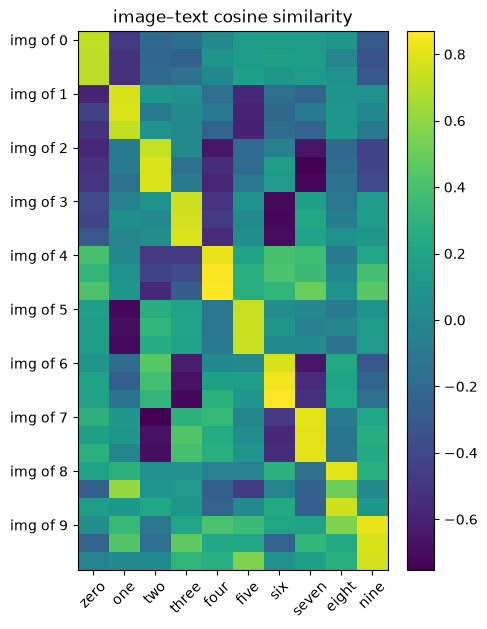

In [6]:
with torch.no_grad():
    zt = txt_enc(encode_text([f"a photo of the digit {names[k]}" for k in range(10)]))
    order = torch.cat([torch.where(yte == k)[0][:3] for k in range(10)])
    S = (img_enc(Xte[order]) @ zt.T).cpu()
plt.figure(figsize=(5, 7)); plt.imshow(S, aspect="auto", cmap="viridis")
plt.xticks(range(10), names, rotation=45); plt.yticks(range(0, 30, 3), [f"img of {k}" for k in range(10)])
plt.title("image–text cosine similarity"); plt.colorbar(); plt.show()